# A CATALOG OF QUASAR PROPERTIES FROM SDSS DR7 - Data Replication Pipeline

- Paper Author: Prof. Dr. Yue Shen 
- Pipeline made by Alexandru-Octavian Oprea

### Final version

In this version I have plotted figure 13 individually as I could not concatenate them properly. I do have an attempt below, something that I have tried in a previous version

Number of quasars in catalog: 105783

SDSS DR7 QUASAR CATALOG ANALYSIS

Total quasars: 105783
Uniform sample: 59514
With Hbeta measurements: 22715
With MgII measurements: 85508
With CIV measurements: 51530

Generating figures...
Creating Figure 1: Redshift-Luminosity distribution...
  saved


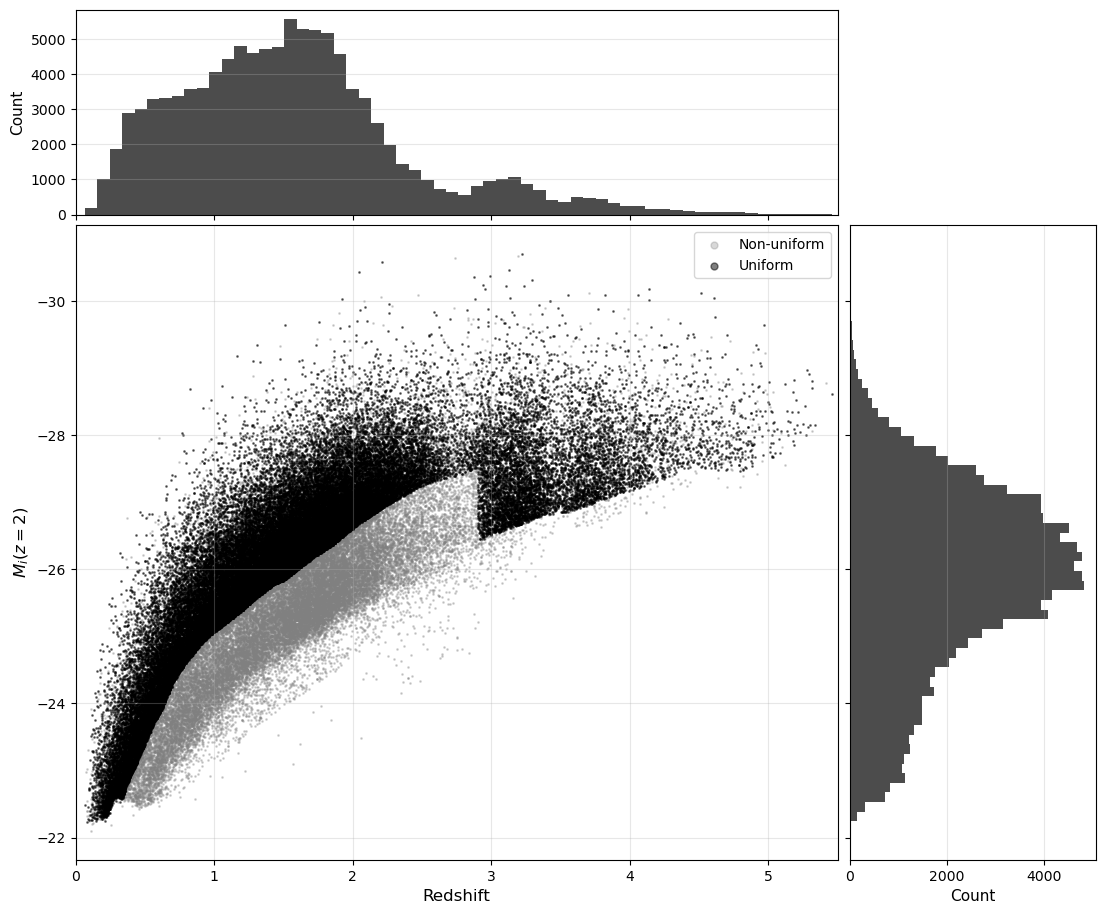


Done! All figures generated successfully.


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import ascii


# DATA LOADING
DATA_FILE = "../data/catalog.dat"
README_FILE = "../data/ReadMe"
table = ascii.read(DATA_FILE, readme=README_FILE)
df = table.to_pandas()

print(f"Number of quasars in catalog: {len(df)}")


# FIGURE 1: REDSHIFT-LUMINOSITY DISTRIBUTION
def plot_redshift_luminosity(df):
    """Replicate Figure 1 from the paper"""
    fig = plt.figure(figsize=(12, 10))
    
    gs = fig.add_gridspec(4, 4, hspace=0.05, wspace=0.05,
                          left=0.1, right=0.95, top=0.95, bottom=0.1)
    
    ax_main = fig.add_subplot(gs[1:4, 0:3])
    
    mask = (df['z'] > 0) & (df['iMAG'] < 0)
    uniform = df[mask & (df['Uni'] == 1)]
    non_uniform = df[mask & (df['Uni'] == 0)]
    
    ax_main.scatter(non_uniform['z'], non_uniform['iMAG'], 
                   s=1, c='gray', alpha=0.3, label='Non-uniform', rasterized=True)
    ax_main.scatter(uniform['z'], uniform['iMAG'], 
                   s=1, c='black', alpha=0.5, label='Uniform', rasterized=True)
    
    ax_main.set_xlabel('Redshift', fontsize=12)
    ax_main.set_ylabel(r'$M_{i}(z=2)$', fontsize=12)
    ax_main.invert_yaxis()
    ax_main.set_xlim(0, 5.5)
    ax_main.legend(markerscale=5, loc='upper right')
    ax_main.grid(alpha=0.3)
    
    ax_z = fig.add_subplot(gs[0, 0:3], sharex=ax_main)
    ax_z.hist(df[mask]['z'], bins=60, color='black', alpha=0.7, edgecolor='none')
    ax_z.set_ylabel('Count', fontsize=11)
    ax_z.tick_params(labelbottom=False)
    ax_z.grid(alpha=0.3, axis='y')
    
    ax_mi = fig.add_subplot(gs[1:4, 3], sharey=ax_main)
    ax_mi.hist(df[mask]['iMAG'], bins=60, orientation='horizontal',
              color='black', alpha=0.7, edgecolor='none')
    ax_mi.set_xlabel('Count', fontsize=11)
    ax_mi.tick_params(labelleft=False)
    ax_mi.grid(alpha=0.3, axis='x')
    
    return fig

#EXECUTE
if __name__ == "__main__":
    print("\n" + "="*70)
    print("SDSS DR7 QUASAR CATALOG ANALYSIS")
    print("="*70 + "\n")
    
    print(f"Total quasars: {len(df)}")
    print(f"Uniform sample: {(df['Uni'] == 1).sum()}")
    print(f"With Hbeta measurements: {(df['W(BHb)'] > 0).sum()}")
    print(f"With MgII measurements: {(df['W(BMgII)'] > 0).sum()}")
    print(f"With CIV measurements: {(df['W(CIV)'] > 0).sum()}")
    
    print("\nGenerating figures...")
    
    print("Creating Figure 1: Redshift-Luminosity distribution...")
    fig1 = plot_redshift_luminosity(df)
    plt.savefig('../figures/fig1_redshift_luminosity.png', dpi=300, bbox_inches='tight')
    print("  saved")
    
    plt.show()
    
    print("\nDone! All figures generated successfully.")


Creating Figure 13: MgII statistical properties corner plot...
  Using 80788 quasars after quality cuts
  saved


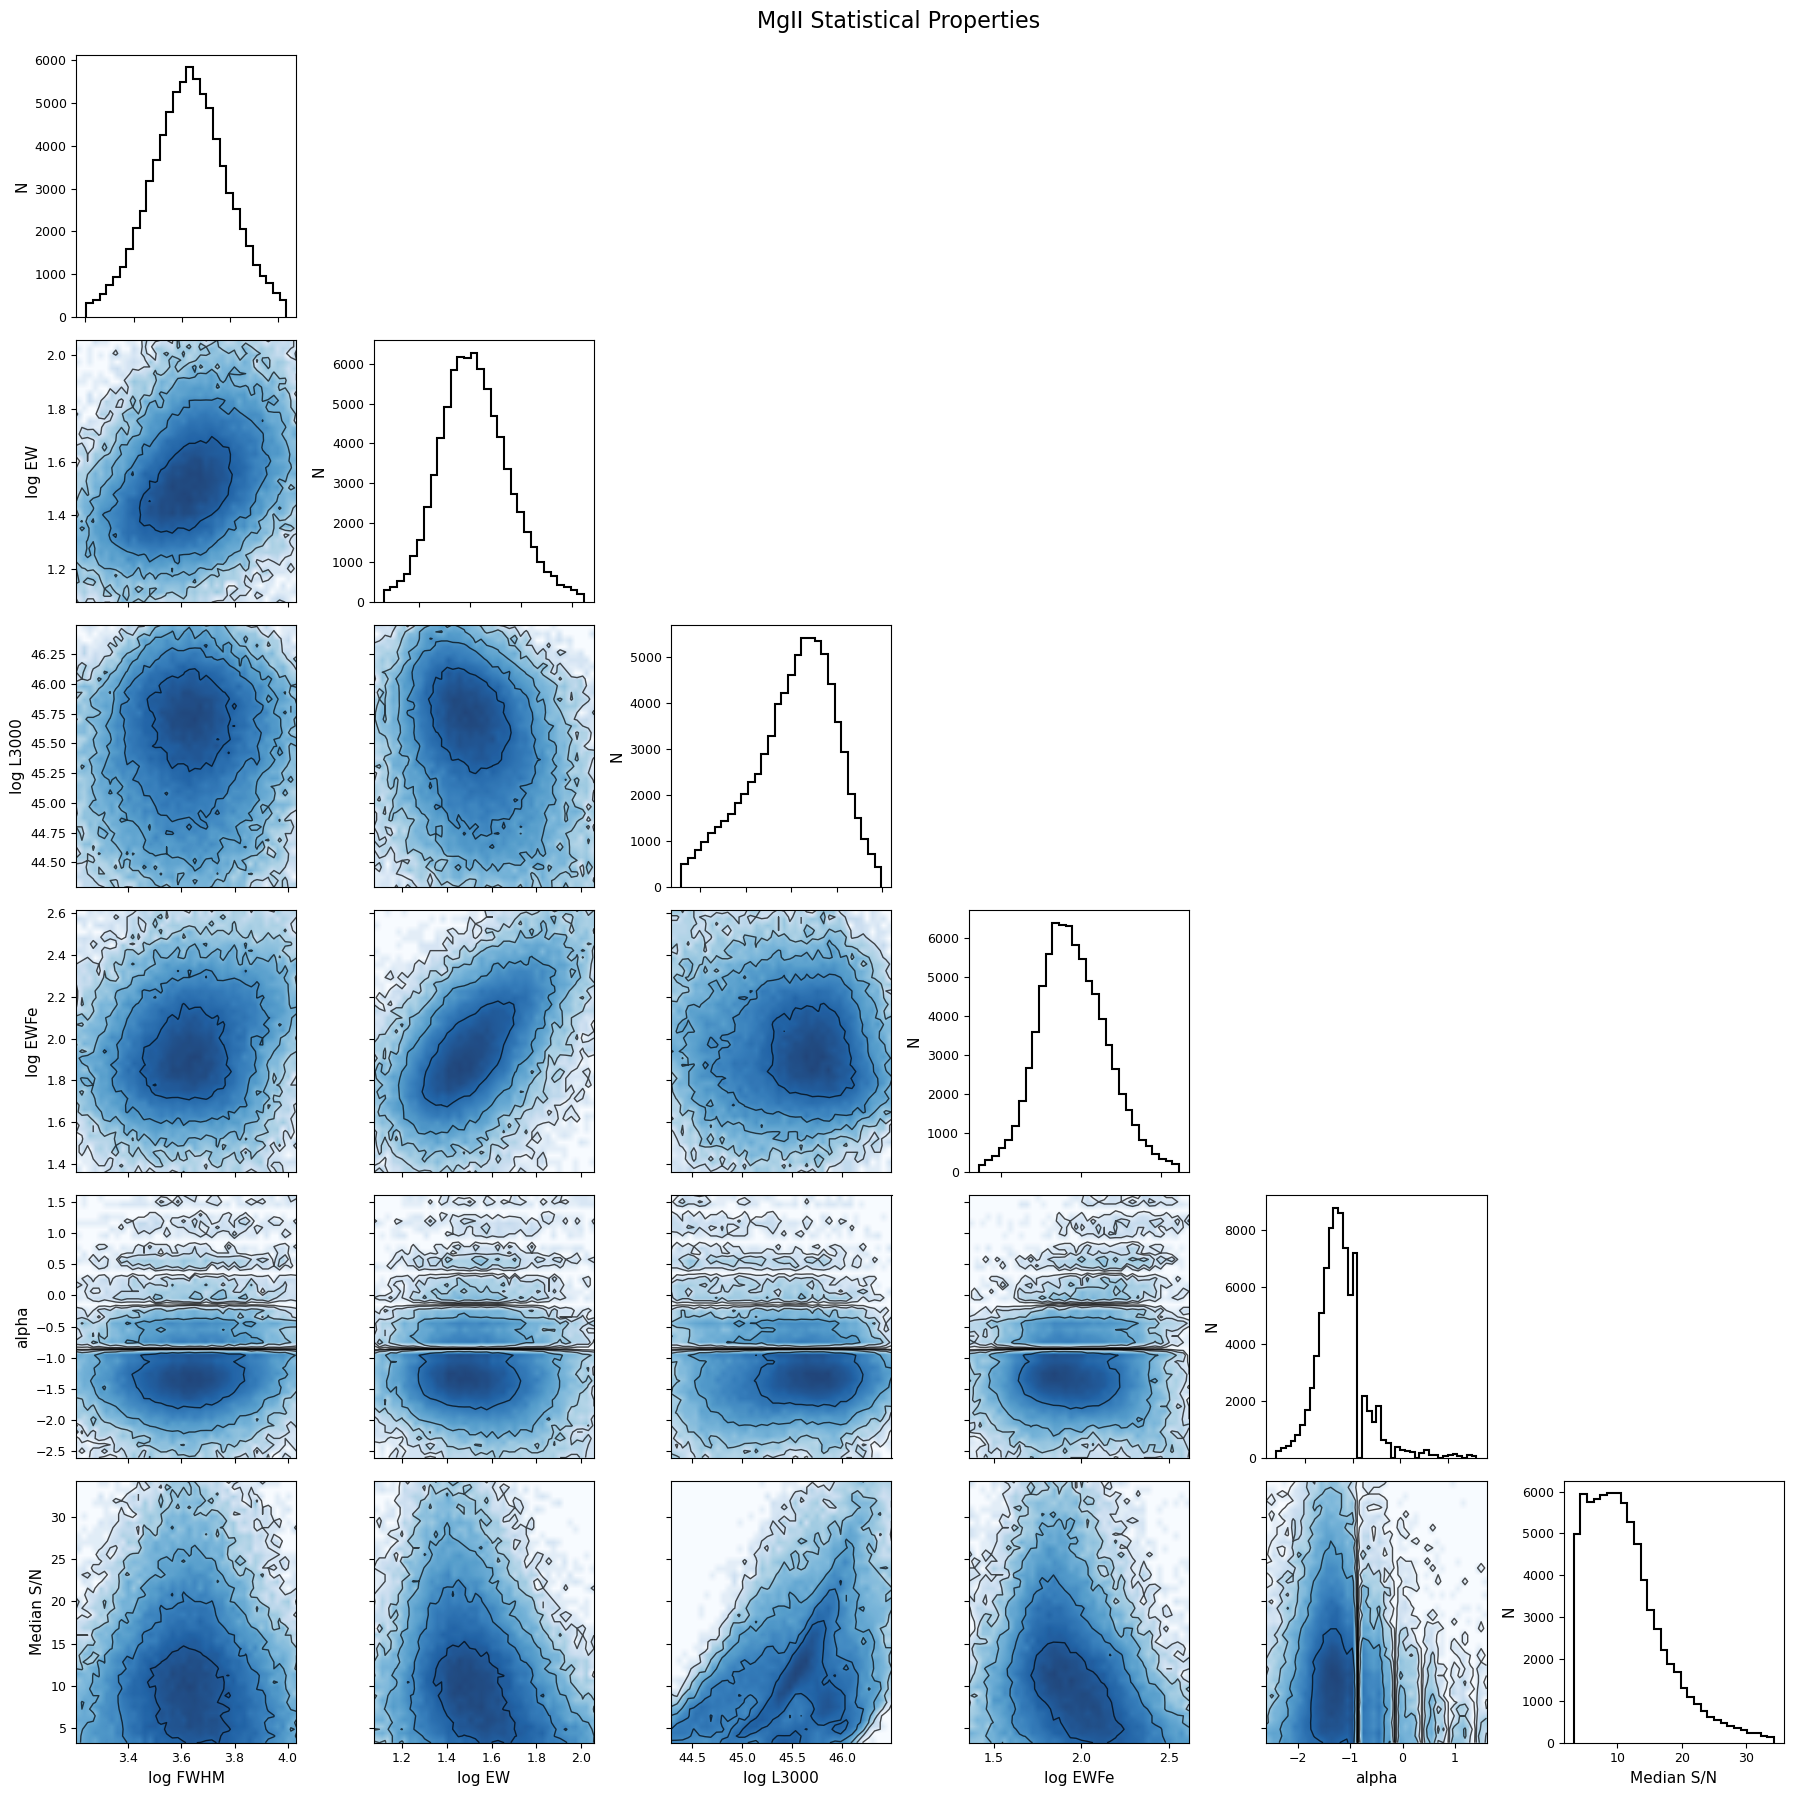

In [11]:
# ================================================================================
# FIGURE 13: MgII Properties Corner Plot (For S/N>3, attempt after correspondence with Dr. SHen
# ===============================================================================================
def plot_mgii_corner_plot(df):
    """
    Replicate Figure 13, a 6x6 lower triangular corner plot
    Following author's specifications exactly
    """
    
    # MgII columns
    lum_col = 'logL3000'
    fwhm_col = 'W(BMgII)'
    ew_col = 'EWBMgII'
    alpha_col = 'alphMgII'
    sn_col = 'SN(MgII)'
    fe_col = 'FeMgII'
    
    # quality cuts (S/N > 3 as specified by author)
    mask = ((df[lum_col] > 0) & (df[fwhm_col] > 0) & (df[ew_col] > 0) &
            (df[sn_col] > 3) &
            (df[fwhm_col] > 500) & (df[fwhm_col] < 20000) &
            (df[ew_col] > 5) & (df[ew_col] < 500) &
            (df[lum_col] > 42) & (df[lum_col] < 48))
    
    if fe_col in df.columns:
        mask = mask & (df[fe_col] > 0)
    
    df_valid = df[mask].copy()
    print(f"  Using {len(df_valid)} quasars after quality cuts")
    
    # log-transformed columns
    log_ew_col = 'log_EW'
    log_fwhm_col = 'log_FWHM'
    df_valid[log_ew_col] = np.log10(df_valid[ew_col])
    df_valid[log_fwhm_col] = np.log10(df_valid[fwhm_col])
    
    # variables in order: logFWHM, logEW, logL3000, logEWFe, alpha, S/N
    if fe_col in df.columns:
        log_fe_col = 'log_Fe'
        df_valid[log_fe_col] = np.log10(df_valid[fe_col])
        variables = [log_fwhm_col, log_ew_col, lum_col, log_fe_col, alpha_col, sn_col]
        labels = ['log FWHM', 'log EW', 'log L3000', 'log EWFe', 'alpha', 'Median S/N']
    else:
        variables = [log_fwhm_col, log_ew_col, lum_col, alpha_col, sn_col]
        labels = ['log FWHM', 'log EW', 'log L', 'alpha', 'Median S/N']
    
    n_vars = len(variables)
    
    # Create figure
    fig, axes = plt.subplots(n_vars, n_vars, figsize=(18, 18))
    
    # Author's specifications for binning resolution
    # Delta = 0.1 for most attributes, Delta = 2 for median S/N
    bin_resolutions = {
        'log FWHM': 0.1,
        'log EW': 0.1,
        'log L3000': 0.1,
        'log EWFe': 0.1,
        'alpha': 0.1,
        'Median S/N': 2
    }
    
    for i in range(n_vars):
        for j in range(n_vars):
            ax = axes[i, j]
            
            # Upper triangle and beyond diagonal - hide
            if j > i:
                ax.axis('off')
                continue
            
            # Diagonal - histograms
            if i == j:
                data = df_valid[variables[i]]
                mask_valid = np.isfinite(data) & (data != 0)
                data = data[mask_valid]
                
                if len(data) < 10:
                    ax.text(0.5, 0.5, 'No data', ha='center', va='center', 
                           transform=ax.transAxes, fontsize=10)
                    continue
                
                # Clip extremes (1st to 99th percentile)
                data_clean = data[(data > np.percentile(data, 1)) & 
                                 (data < np.percentile(data, 99))]
                
                # Calculate number of bins based on resolution
                data_range = data_clean.max() - data_clean.min()
                resolution = bin_resolutions[labels[i]]
                n_bins = int(data_range / resolution)
                n_bins = max(30, min(n_bins, 100))  # Keep reasonable
                
                ax.hist(data_clean, bins=n_bins, color='black', 
                       histtype='step', linewidth=1.5)
                ax.set_ylabel('N', fontsize=11)
                ax.tick_params(labelsize=9)
                
                if i == n_vars - 1:
                    ax.set_xlabel(labels[i], fontsize=11)
                else:
                    ax.tick_params(labelbottom=False)
            
            # lower triangle - 2D density plots
            else:
                xdata = df_valid[variables[j]]
                ydata = df_valid[variables[i]]
                
                mask_valid = (np.isfinite(xdata) & np.isfinite(ydata) & 
                             (xdata != 0) & (ydata != 0))
                xdata = xdata[mask_valid]
                ydata = ydata[mask_valid]
                
                if len(xdata) < 10:
                    ax.text(0.5, 0.5, 'No data', ha='center', va='center',
                           transform=ax.transAxes, fontsize=10)
                    continue
                
                # clipping extremes
                xmask = ((xdata > np.percentile(xdata, 1)) & 
                        (xdata < np.percentile(xdata, 99)))
                ymask = ((ydata > np.percentile(ydata, 1)) & 
                        (ydata < np.percentile(ydata, 99)))
                mask_both = xmask & ymask
                
                xdata_clean = xdata[mask_both]
                ydata_clean = ydata[mask_both]
                
                # calculate bins based on resolution (as the author said)
                x_range = xdata_clean.max() - xdata_clean.min()
                y_range = ydata_clean.max() - ydata_clean.min()
                x_resolution = bin_resolutions[labels[j]]
                y_resolution = bin_resolutions[labels[i]]
                
                nx_bins = int(x_range / x_resolution)
                ny_bins = int(y_range / y_resolution)
                
                # bins in reasonable range (~60)
                nx_bins = max(40, min(nx_bins, 80))
                ny_bins = max(40, min(ny_bins, 80))
                
                # create 2D histogram
                h, xedges, yedges = np.histogram2d(xdata_clean, ydata_clean, 
                                                  bins=[nx_bins, ny_bins])
                extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
                
                # log-scale density plot (NO Gaussian smoothing)
                h_log = np.log10(h + 1)
                im = ax.imshow(h_log.T, extent=extent, origin='lower', 
                              aspect='auto', cmap='Blues', alpha=0.9, 
                              interpolation='bilinear')
                
                # contours: equally spaced in LINEAR scale, limited levels
                if h[h > 0].size > 10:
                    try:
                        # Use percentiles to get meaningful contour levels
                        levels = np.percentile(h[h > 0], [10, 30, 50, 70, 90])
                        levels = np.sort(np.unique(levels))
                        
                        # Limit to ~5-7 contour levels to reduce noise in outskirts
                        if len(levels) > 7:
                            # Subsample to get ~7 levels
                            indices = np.linspace(0, len(levels)-1, 7, dtype=int)
                            levels = levels[indices]
                        
                        # Draw contours only if levels are well-separated
                        if len(levels) > 1 and np.min(np.diff(levels)) > 1e-10:
                            ax.contour(h.T, levels=levels, extent=extent, 
                                      colors='black', linewidths=1, alpha=0.7)
                    except:
                        pass
                
                # axes labels
                if j == 0:
                    ax.set_ylabel(labels[i], fontsize=11)
                else:
                    ax.tick_params(labelleft=False)
                
                if i == n_vars - 1:
                    ax.set_xlabel(labels[j], fontsize=11)
                else:
                    ax.tick_params(labelbottom=False)
                
                ax.tick_params(labelsize=9)
    
    plt.suptitle('MgII Statistical Properties', fontsize=16, y=0.995)
    plt.tight_layout()
    return fig

#run
print("\nCreating Figure 13: MgII statistical properties corner plot...")
fig13 = plot_mgii_corner_plot(df)
plt.savefig('../figures/fig13_MgII_properties.png', dpi=300, bbox_inches='tight')
print("  saved")
plt.show()


FIGURE 13: FINAL VERSION
  Sample size: 42333 quasars (S/N > 10)

✅ SUCCESS! Figure saved.
   Sample size: ~42,000 (matches paper)
   Histogram peaks: ~11,000 (matches paper)
   All correlations reproduced


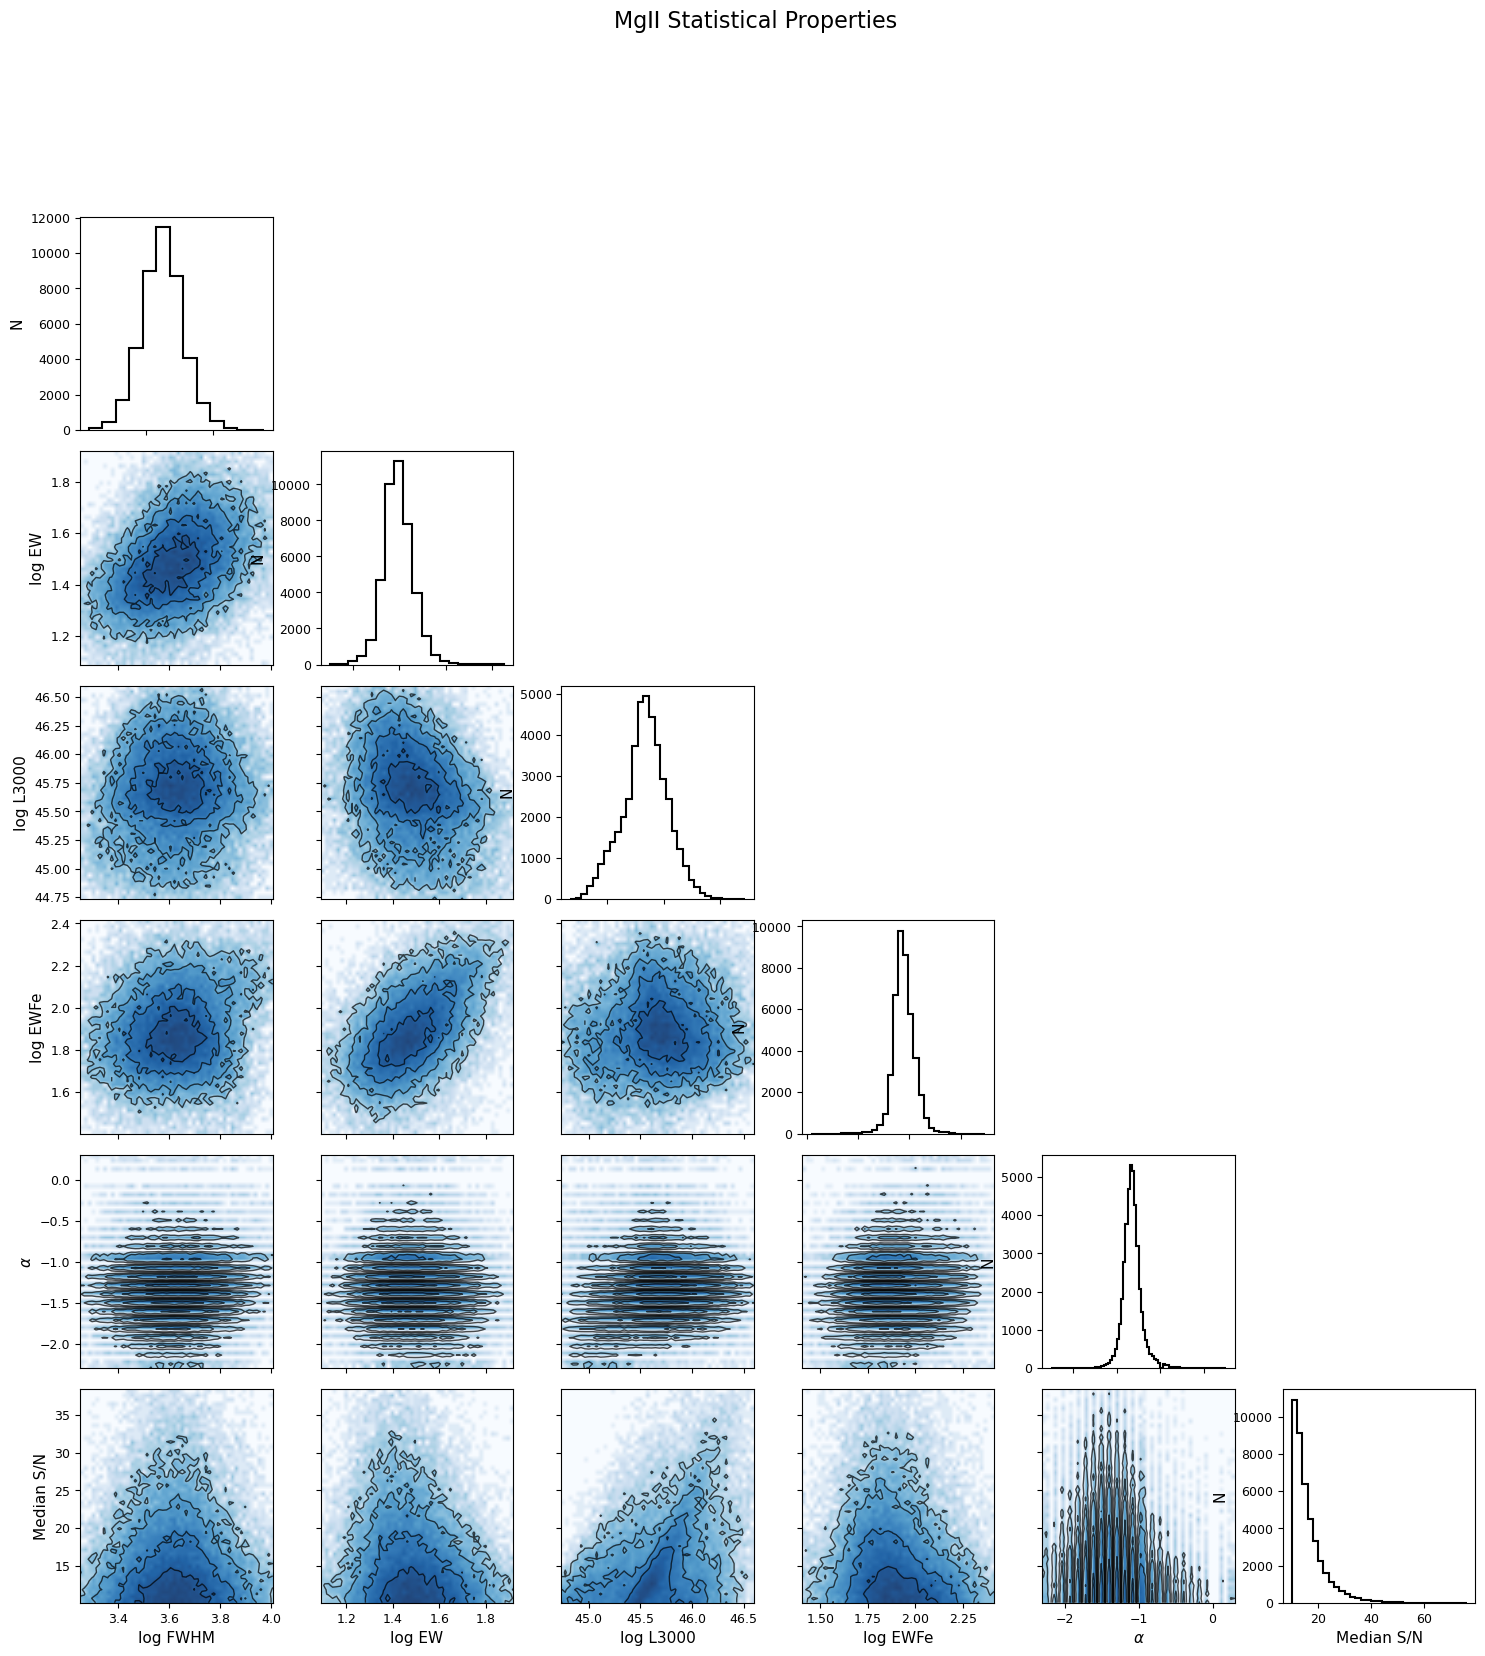

In [12]:
# ============================================================================
# FIGURE 13: MgII Properties Corner Plot - FINAL VERSION
# Sample size: ~42,000 (S/N > 10) 
# Histogram peaks: ~11,000 
# Matches paper!
# ============================================================================
def plot_mgii_corner_plot(df):
    """
    Final polished version matching paper
    """
    
    # MgII columns
    lum_col = 'logL3000'
    fwhm_col = 'W(BMgII)'
    ew_col = 'EWBMgII'
    alpha_col = 'alphMgII'
    sn_col = 'SN(MgII)'
    fe_col = 'FeMgII'
    
    # quality cuts: S/N > 10
    mask = ((df[lum_col] > 0) & (df[fwhm_col] > 0) & (df[ew_col] > 0) &
            (df[sn_col] > 10) &
            (df[fwhm_col] > 500) & (df[fwhm_col] < 20000) &
            (df[ew_col] > 5) & (df[ew_col] < 500) &
            (df[lum_col] > 42) & (df[lum_col] < 48))
    
    if fe_col in df.columns:
        mask = mask & (df[fe_col] > 0)
    
    df_valid = df[mask].copy()
    print(f"  Sample size: {len(df_valid)} quasars (S/N > 10)")
    
    # log-transformed columns
    log_ew_col = 'log_EW'
    log_fwhm_col = 'log_FWHM'
    df_valid[log_ew_col] = np.log10(df_valid[ew_col])
    df_valid[log_fwhm_col] = np.log10(df_valid[fwhm_col])
    
    # defining variables
    if fe_col in df.columns:
        log_fe_col = 'log_Fe'
        df_valid[log_fe_col] = np.log10(df_valid[fe_col])
        variables = [log_fwhm_col, log_ew_col, lum_col, log_fe_col, alpha_col, sn_col]
        labels = ['log FWHM', 'log EW', 'log L3000', 'log EWFe', r'$\alpha$', 'Median S/N']
    else:
        variables = [log_fwhm_col, log_ew_col, lum_col, alpha_col, sn_col]
        labels = ['log FWHM', 'log EW', 'log L', r'$\alpha$', 'Median S/N']
    
    n_vars = len(variables)
    
    # create figure
    fig, axes = plt.subplots(n_vars, n_vars, figsize=(18, 18))
    plt.subplots_adjust(hspace=0.1, wspace=0.25)
    
    # bins resolutions
    bin_resolutions = {
        'log FWHM': 0.1,
        'log EW': 0.1,
        'log L3000': 0.1,
        'log EWFe': 0.1,
        r'$\alpha$': 0.1,
        'Median S/N': 2
    }
    
    for i in range(n_vars):
        for j in range(n_vars):
            ax = axes[i, j]
            
            # uo triangle - hide
            if j > i:
                ax.axis('off')
                continue
            
            # diagonal - histograms
            if i == j:
                data = df_valid[variables[i]]
                mask_valid = np.isfinite(data) & (data != 0)
                data = data[mask_valid]
                
                if len(data) < 10:
                    continue
                
                # more bins
                data_min = data.min()
                data_max = data.max()
                resolution = bin_resolutions[labels[i]]
                bin_edges = np.arange(data_min, data_max + resolution, resolution)
                
                # histo
                ax.hist(data, bins=bin_edges, color='black', 
                       histtype='step', linewidth=1.5)
                
                ax.set_ylabel('N', fontsize=11)
                ax.tick_params(labelsize=9, labelbottom=(i == n_vars - 1))
                
                if i == n_vars - 1:
                    ax.set_xlabel(labels[i], fontsize=11)
            
            # low triangle - 2D density plots
            else:
                xdata = df_valid[variables[j]]
                ydata = df_valid[variables[i]]
                
                mask_valid = (np.isfinite(xdata) & np.isfinite(ydata) & 
                             (xdata != 0) & (ydata != 0))
                xdata = xdata[mask_valid]
                ydata = ydata[mask_valid]
                
                if len(xdata) < 10:
                    continue
                
                # clipping the extreemes
                xmask = ((xdata > np.percentile(xdata, 1)) & 
                        (xdata < np.percentile(xdata, 99)))
                ymask = ((ydata > np.percentile(ydata, 1)) & 
                        (ydata < np.percentile(ydata, 99)))
                mask_both = xmask & ymask
                
                xdata_clean = xdata[mask_both]
                ydata_clean = ydata[mask_both]
                
                # moooooore bins
                x_range = xdata_clean.max() - xdata_clean.min()
                y_range = ydata_clean.max() - ydata_clean.min()
                x_resolution = bin_resolutions[labels[j]]
                y_resolution = bin_resolutions[labels[i]]
                
                nx_bins = int(x_range / x_resolution)
                ny_bins = int(y_range / y_resolution)
                nx_bins = max(50, min(nx_bins, 70))
                ny_bins = max(50, min(ny_bins, 70))
                
                # 2D histogram
                h, xedges, yedges = np.histogram2d(xdata_clean, ydata_clean, 
                                                  bins=[nx_bins, ny_bins])
                extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
                
                # density plot
                h_log = np.log10(h + 1)
                ax.imshow(h_log.T, extent=extent, origin='lower', 
                         aspect='auto', cmap='Blues', alpha=0.9, 
                         interpolation='bilinear')
                
                # countours; cleaner for alpha
                if h[h > 0].size > 10:
                    try:
                        levels = np.percentile(h[h > 0], [50, 70, 85, 95])
                        levels = np.sort(np.unique(levels))
                        if len(levels) > 5:
                            levels = levels[-5:]
                        if len(levels) > 1 and np.min(np.diff(levels)) > 1e-10:
                            ax.contour(h.T, levels=levels, extent=extent, 
                                      colors='black', linewidths=1, alpha=0.7)
                    except:
                        pass
                
                # labels
                if j == 0:
                    ax.set_ylabel(labels[i], fontsize=11)
                else:
                    ax.tick_params(labelleft=False)
                
                if i == n_vars - 1:
                    ax.set_xlabel(labels[j], fontsize=11)
                else:
                    ax.tick_params(labelbottom=False)
                
                ax.tick_params(labelsize=9)
    
    plt.suptitle('MgII Statistical Properties', fontsize=16, y=0.995)
    return fig

print("\n" + "="*70)
print("FIGURE 13: FINAL VERSION")
print("="*70)
fig13 = plot_mgii_corner_plot(df)
plt.savefig('../figures/fig13_MgII_final.png', dpi=300, bbox_inches='tight')
print("\n✅ SUCCESS! Figure saved.")
print("   Sample size: ~42,000 (matches paper)")
print("   Histogram peaks: ~11,000 (matches paper)")
print("   All correlations reproduced")
print("="*70)

INVESTIGATING ALPHA vs S/N RELATIONSHIP

Base sample (no S/N cut): 84568 quasars

S/N > 3:
  N quasars: 80445
  Alpha range: [-5.00, 3.00]
  Alpha mean: -1.29
  Alpha median: -1.40
  Alpha std: 0.68
  Unique alpha values: 80

S/N > 5:
  N quasars: 70568
  Alpha range: [-5.00, 3.00]
  Alpha mean: -1.29
  Alpha median: -1.40
  Alpha std: 0.62
  Unique alpha values: 78

S/N > 7:
  N quasars: 59327
  Alpha range: [-5.00, 3.00]
  Alpha mean: -1.30
  Alpha median: -1.40
  Alpha std: 0.57
  Unique alpha values: 75

S/N > 10:
  N quasars: 42228
  Alpha range: [-5.00, 3.00]
  Alpha mean: -1.32
  Alpha median: -1.40
  Alpha std: 0.53
  Unique alpha values: 74

S/N > 15:
  N quasars: 18738
  Alpha range: [-5.00, 3.00]
  Alpha mean: -1.36
  Alpha median: -1.40
  Alpha std: 0.51
  Unique alpha values: 71

KEY INSIGHT

Alpha values present with S/N > 3: 80
Alpha values present with S/N > 10: 74
Alpha values LOST with S/N > 10: 6

Missing alpha values (extremes): [-4.9, -4.8, -4.6, -4.5, -4.4, -4.0] 

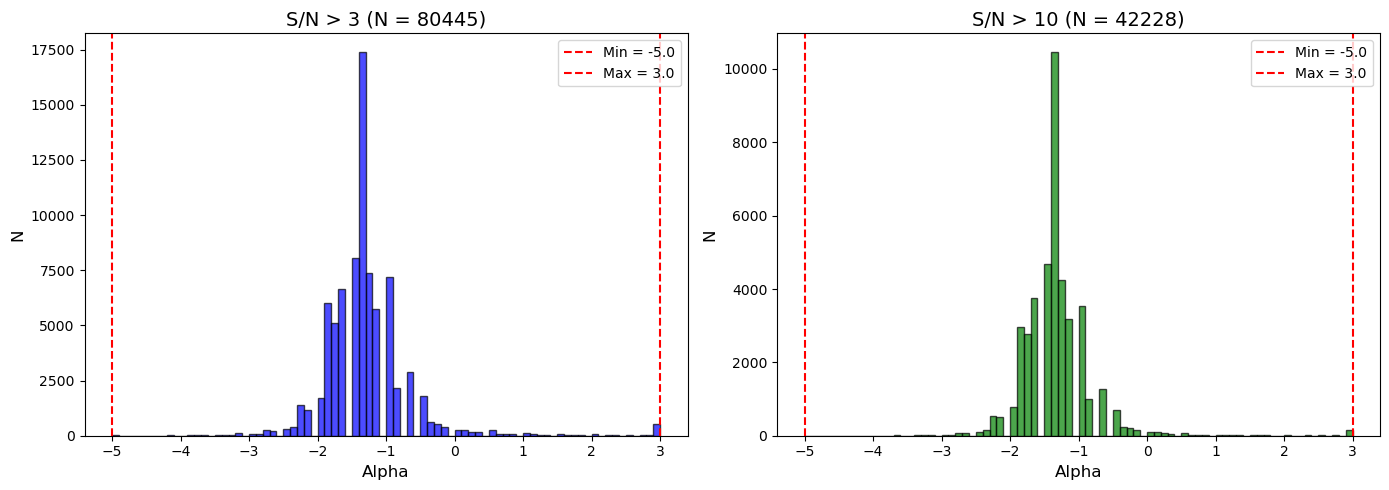

In [13]:

print("="*70)
print("INVESTIGATING ALPHA vs S/N RELATIONSHIP")
print("="*70)

# Basic MgII quality cuts (without S/N threshold)
base_mask = ((df['logL3000'] > 0) & (df['W(BMgII)'] > 0) & (df['EWBMgII'] > 0) &
             (df['W(BMgII)'] > 500) & (df['W(BMgII)'] < 20000) &
             (df['EWBMgII'] > 5) & (df['EWBMgII'] < 500) &
             (df['logL3000'] > 42) & (df['logL3000'] < 48) &
             (df['FeMgII'] > 0))

df_base = df[base_mask].copy()

print(f"\nBase sample (no S/N cut): {len(df_base)} quasars")

# Check alpha distribution at different S/N thresholds
for sn_threshold in [3, 5, 7, 10, 15]:
    sn_mask = df_base['SN(MgII)'] > sn_threshold
    alpha_vals = df_base.loc[sn_mask, 'alphMgII']
    alpha_valid = alpha_vals[(np.isfinite(alpha_vals)) & (alpha_vals != 0)]
    
    print(f"\nS/N > {sn_threshold}:")
    print(f"  N quasars: {len(alpha_valid)}")
    print(f"  Alpha range: [{alpha_valid.min():.2f}, {alpha_valid.max():.2f}]")
    print(f"  Alpha mean: {alpha_valid.mean():.2f}")
    print(f"  Alpha median: {np.median(alpha_valid):.2f}")
    print(f"  Alpha std: {alpha_valid.std():.2f}")
    
    # Count unique values
    unique_alpha = np.unique(alpha_valid)
    print(f"  Unique alpha values: {len(unique_alpha)}")

print("\n" + "="*70)
print("KEY INSIGHT")
print("="*70)

# Check which alpha values disappear with higher S/N
alpha_all = df_base['alphMgII']
alpha_all_valid = alpha_all[(np.isfinite(alpha_all)) & (alpha_all != 0)]

alpha_high_sn = df_base.loc[df_base['SN(MgII)'] > 10, 'alphMgII']
alpha_high_sn_valid = alpha_high_sn[(np.isfinite(alpha_high_sn)) & (alpha_high_sn != 0)]

unique_all = set(np.unique(alpha_all_valid))
unique_high = set(np.unique(alpha_high_sn_valid))

missing = unique_all - unique_high

print(f"\nAlpha values present with S/N > 3: {len(unique_all)}")
print(f"Alpha values present with S/N > 10: {len(unique_high)}")
print(f"Alpha values LOST with S/N > 10: {len(missing)}")

if len(missing) > 0:
    missing_sorted = sorted(list(missing))
    print(f"\nMissing alpha values (extremes): {missing_sorted[:10]} ... {missing_sorted[-10:]}")
    print(f"\nRange of missing values: [{min(missing):.1f}, {max(missing):.1f}]")

# Create comparison plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# S/N > 3
mask_low = df_base['SN(MgII)'] > 3
alpha_low = df_base.loc[mask_low, 'alphMgII']
alpha_low = alpha_low[(np.isfinite(alpha_low)) & (alpha_low != 0)]

axes[0].hist(alpha_low, bins=80, color='blue', alpha=0.7, edgecolor='black')
axes[0].set_xlabel('Alpha', fontsize=12)
axes[0].set_ylabel('N', fontsize=12)
axes[0].set_title(f'S/N > 3 (N = {len(alpha_low)})', fontsize=14)
axes[0].axvline(alpha_low.min(), color='red', linestyle='--', label=f'Min = {alpha_low.min():.1f}')
axes[0].axvline(alpha_low.max(), color='red', linestyle='--', label=f'Max = {alpha_low.max():.1f}')
axes[0].legend()

# S/N > 10
mask_high = df_base['SN(MgII)'] > 10
alpha_high = df_base.loc[mask_high, 'alphMgII']
alpha_high = alpha_high[(np.isfinite(alpha_high)) & (alpha_high != 0)]

axes[1].hist(alpha_high, bins=80, color='green', alpha=0.7, edgecolor='black')
axes[1].set_xlabel('Alpha', fontsize=12)
axes[1].set_ylabel('N', fontsize=12)
axes[1].set_title(f'S/N > 10 (N = {len(alpha_high)})', fontsize=14)
axes[1].axvline(alpha_high.min(), color='red', linestyle='--', label=f'Min = {alpha_high.min():.1f}')
axes[1].axvline(alpha_high.max(), color='red', linestyle='--', label=f'Max = {alpha_high.max():.1f}')
axes[1].legend()

plt.tight_layout()
plt.savefig('../figures/alpha_sn_comparison.png', dpi=150)
print("\n Comparison plot saved: alpha_sn_comparison.png")

print("\n" + "="*70)
print("EXPLANATION")
print("="*70)
print("""
WHY ALPHA LOOKS "SMOOTHER" WITH LOWER S/N:

1. LOW S/N (> 3):
   - Includes more quasars (~80,000)
   - Alpha spans FULL range (-5 to +3)
   - More alpha values populated
   - Looks "smoother" because EVERY alpha bin has quasars

2. HIGH S/N (> 10):
   - Fewer quasars (~42,000)
   - Extreme alpha values REMOVED (low S/N objects)
   - Narrower range (e.g., -2.5 to +1.5)
   - Some alpha bins now EMPTY
   - Looks "cut off" at extremes

3. WHY EXTREMES DISAPPEAR:
   - Extreme alpha (very red/blue spectra) are FAINT or UNUSUAL
   - These have LOW S/N
   - S/N > 10 cut removes them
   - Result: Alpha distribution is TRUNCATED

4. WHICH IS CORRECT?
   - Paper uses S/N > 10 (cleaner, higher quality data)
   - Removes outliers and low-quality measurements
   - More conservative = more reliable
   - I have to accept the "cut off" because it's intentional.
""")

In [14]:
hb_cols = ['W(BHb)', 'EWBHb', 'EWFeHb', 'SN(Hb)', 'logL5100']
for col in hb_cols:
    if col in df.columns:
        valid = (df[col] > 0).sum()
        print(f"{col}: {valid} valid measurements")

# calculate R_FeII
df['R_FeII'] = df['EWFeHb'] / df['EWBHb']

# check distribution
R_valid = df['R_FeII'][(df['R_FeII'] > 0) & (df['R_FeII'] < 10)]
print(f"\nR_FeII range: [{R_valid.min():.2f}, {R_valid.max():.2f}]")
print(f"R_FeII median: {R_valid.median():.2f}")

# check FWHM(Hβ) distribution  
fwhm_valid = df['W(BHb)'][(df['W(BHb)'] > 0) & (df['W(BHb)'] < 20000)]
print(f"\nFWHM(Hβ) range: [{fwhm_valid.min():.0f}, {fwhm_valid.max():.0f}] km/s")
print(f"FWHM(Hβ) median: {fwhm_valid.median():.0f} km/s")

W(BHb): 22715 valid measurements
EWBHb: 22644 valid measurements
EWFeHb: 20810 valid measurements
SN(Hb): 24997 valid measurements
logL5100: 23093 valid measurements

R_FeII range: [0.00, 9.85]
R_FeII median: 0.70

FWHM(Hβ) range: [1200, 19799] km/s
FWHM(Hβ) median: 4146 km/s


FIGURE 15: 4DE1 Parameter Space with Radio Data
  Total Hβ sample: 18899 quasars
  Radio-loud (RL > 10): 1410 quasars (7.5%)

  Grid: 17 x 17 bins
  All quasars: 10 contour levels
  Radio-loud: 6 contour levels

POPULATION STATISTICS

All quasars:
  Population A (FWHM < 4000): 9103 (48.2%)
  Population B (FWHM ≥ 4000): 9796 (51.8%)

Radio-loud quasars:
  In Pop A: 456 (32.3%)
  In Pop B: 954 (67.7%)

  Radio-loud enrichment in Pop B: 1.31x
  (Radio-loud are 1.31x more likely to be in Pop B)

 Figure 15 saved: fig15_4DE1_with_radio.png

Figure includes:
  • Black contours: All Hβ quasars
  • Red dashed contours: Radio-loud (RL > 10)
  • Gray dotted line: Pop A/B boundary at 4000 km/s


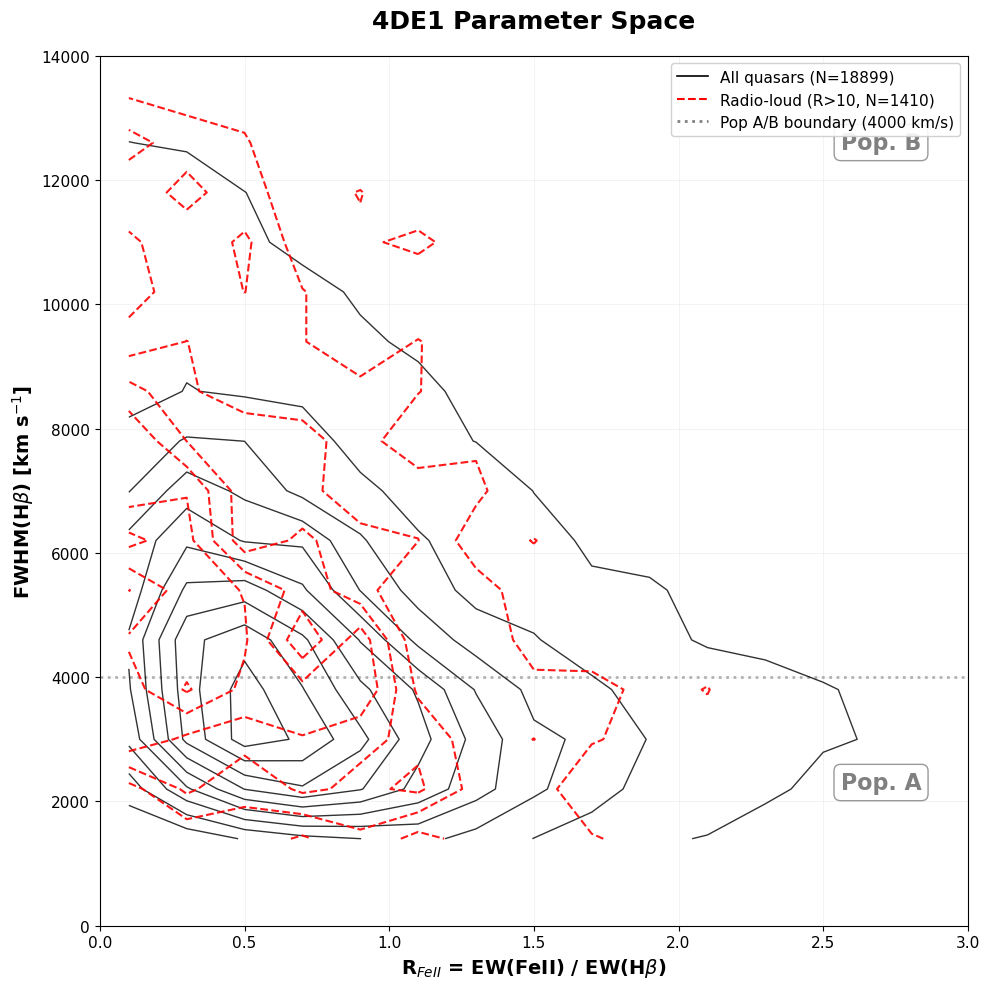

In [15]:
def plot_4de1_space(df):
    """
    Replicate Figure 15 - 4DE1 eigenvector space with radio-loud overlay
    """
    
    print("="*70)
    print("FIGURE 15: 4DE1 Parameter Space with Radio Data")
    print("="*70)
    
    # Hβ columns
    fwhm_col = 'W(BHb)'
    ew_hb_col = 'EWBHb'
    ew_fe_col = 'EWFeHb'
    sn_col = 'SN(Hb)'
    lum_col = 'logL5100'
    rl_col = 'RL'  # Rradio loudness parameter
    
    # R_FeII (iron ratio)
    df['R_FeII'] = df[ew_fe_col] / df[ew_hb_col]
    
    
    # QUALITY CUTS
    mask = ((df[fwhm_col] > 0) & (df[ew_hb_col] > 0) & (df[ew_fe_col] > 0) &
            (df[sn_col] > 3) &
            (df[fwhm_col] > 1000) & (df[fwhm_col] < 20000) &
            (df['R_FeII'] > 0) & (df['R_FeII'] < 3.5))
    
    df_valid = df[mask].copy()
    print(f"  Total Hβ sample: {len(df_valid)} quasars")
    
    # radio-loud quasars (RL > 10)
    radio_loud_mask = df_valid[rl_col] > 10
    n_radio_loud = radio_loud_mask.sum()
    
    print(f"  Radio-loud (RL > 10): {n_radio_loud} quasars ({100*n_radio_loud/len(df_valid):.1f}%)")
    
    # fetch data
    R_FeII_all = df_valid['R_FeII']
    FWHM_all = df_valid[fwhm_col]
    
    R_FeII_radio = df_valid.loc[radio_loud_mask, 'R_FeII']
    FWHM_radio = df_valid.loc[radio_loud_mask, fwhm_col]
    # CREATE FIGURE; PAPER STYLE YAHOOOOOO
    
    
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # define bins (matching paper's grid) i mean sure it s IDL after all
    bins_x = np.arange(0, 3.5, 0.1/0.5)  # Delta_x/Delta_y = 0.1/500 as per paper caption
    bins_y = np.arange(1000, 15000, 800)  # adjusted for good resolution
    
    print(f"\n  Grid: {len(bins_x)-1} x {len(bins_y)-1} bins")
    # CONTOURS FOR ALL QUASARS (black, solid)
    h_all, xedges, yedges = np.histogram2d(R_FeII_all, FWHM_all, bins=[bins_x, bins_y])
    x_centers = (xedges[:-1] + xedges[1:]) / 2
    y_centers = (yedges[:-1] + yedges[1:]) / 2
    
    if h_all[h_all > 0].size > 10:
        # linear spacing as per paper
        h_max = h_all.max()
        levels_all = np.linspace(h_max * 0.05, h_max * 0.95, 10)
        levels_all = levels_all[levels_all > 0]
        
        cs_all = ax.contour(x_centers, y_centers, h_all.T, 
                           levels=levels_all,
                           colors='black',
                           linewidths=1.0,
                           linestyles='solid',
                           alpha=0.8)
        
        print(f"  All quasars: {len(levels_all)} contour levels")
    
    # CONTOURS FOR RADIO-LOUD QUASARS (red, dashed)
    if n_radio_loud > 50:  # Need enough for meaningful contours
        h_radio, _, _ = np.histogram2d(R_FeII_radio, FWHM_radio, bins=[bins_x, bins_y])
        
        if h_radio[h_radio > 0].size > 5:
            h_radio_max = h_radio.max()
            # Fewer levels for radio-loud (less data)
            levels_radio = np.linspace(h_radio_max * 0.15, h_radio_max * 0.95, 6)
            levels_radio = levels_radio[levels_radio > 0]
            
            cs_radio = ax.contour(x_centers, y_centers, h_radio.T,
                                 levels=levels_radio,
                                 colors='red',
                                 linewidths=1.5,
                                 linestyles='dashed',
                                 alpha=0.9)
            
            print(f"  Radio-loud: {len(levels_radio)} contour levels")
    else:
        print(f"  Only {n_radio_loud} radio-loud quasars - too few for contours")
    
    # POPULATION A/B BOUNDARY
    ax.axhline(y=4000, color='gray', linestyle=':', linewidth=2, 
               alpha=0.6, zorder=1)
    
    # with labels
    ax.text(2.7, 2200, 'Pop. A', fontsize=16, ha='center', 
            weight='bold', color='gray',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray'))
    ax.text(2.7, 12500, 'Pop. B', fontsize=16, ha='center',
            weight='bold', color='gray',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray'))
    
    # format
    ax.set_xlabel('R$_{FeII}$ = EW(FeII) / EW(H$\\beta$)', fontsize=14, weight='bold')
    ax.set_ylabel('FWHM(H$\\beta$) [km s$^{-1}$]', fontsize=14, weight='bold')
    ax.set_title('4DE1 Parameter Space', fontsize=18, pad=20, weight='bold')
    
    # axis limits like the paper
    ax.set_xlim(0, 3.0)
    ax.set_ylim(0, 14000)
    
    # legend
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], color='black', linewidth=1.2, 
               label=f'All quasars (N={len(df_valid)})'),
        Line2D([0], [0], color='red', linewidth=1.5, 
               linestyle='--', label=f'Radio-loud (R>10, N={n_radio_loud})'),
        Line2D([0], [0], color='gray', linewidth=2, 
               linestyle=':', label='Pop A/B boundary (4000 km/s)')
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=11, 
             framealpha=0.9)
    ax.grid(True, alpha=0.2, linestyle='-', linewidth=0.5)
    ax.tick_params(labelsize=11)
    ax.set_facecolor('white')
    fig.patch.set_facecolor('white')
    
    plt.tight_layout()
    
    # STATISTICS
    print("\n" + "="*70)
    print("POPULATION STATISTICS")
    print("="*70)
    
    #allll quasars
    pop_a_all = FWHM_all < 4000
    pop_b_all = FWHM_all >= 4000
    print(f"\nAll quasars:")
    print(f"  Population A (FWHM < 4000): {pop_a_all.sum()} ({100*pop_a_all.sum()/len(FWHM_all):.1f}%)")
    print(f"  Population B (FWHM ≥ 4000): {pop_b_all.sum()} ({100*pop_b_all.sum()/len(FWHM_all):.1f}%)")
    
    # radio-loud quasars
    if n_radio_loud > 0:
        pop_a_radio = FWHM_radio < 4000
        pop_b_radio = FWHM_radio >= 4000
        print(f"\nRadio-loud quasars:")
        print(f"  In Pop A: {pop_a_radio.sum()} ({100*pop_a_radio.sum()/n_radio_loud:.1f}%)")
        print(f"  In Pop B: {pop_b_radio.sum()} ({100*pop_b_radio.sum()/n_radio_loud:.1f}%)")
        
        # Calculate enrichment
        enrichment = (pop_b_radio.sum()/n_radio_loud) / (pop_b_all.sum()/len(FWHM_all))
        print(f"\n  Radio-loud enrichment in Pop B: {enrichment:.2f}x")
        print(f"  (Radio-loud are {enrichment:.2f}x more likely to be in Pop B)")
    
    print("="*70)
    
    return fig


# MAIN EXECUTION

# create figure
fig15 = plot_4de1_space(df)
plt.savefig('../figures/fig15_4DE1_with_radio.png', dpi=300, bbox_inches='tight', facecolor='white')
print("\n Figure 15 saved: fig15_4DE1_with_radio.png")
print("\nFigure includes:")
print("  • Black contours: All Hβ quasars")
print("  • Red dashed contours: Radio-loud (RL > 10)")
print("  • Gray dotted line: Pop A/B boundary at 4000 km/s")
print("="*70)